In [1]:
"https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv"

'https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv'

## Basic DataFrame

Consider the following Python dictionary data and Python list labels:

```
data = {'birds': ['Cranes', 'Cranes', 'plovers', 'spoonbills', 'spoonbills', 'Cranes', 'plovers', 'Cranes', 'spoonbills', 'spoonbills', 'Cranes'],
        'age': [3.5, 4, 1.5, np.nan, 6, 3, 5.5, np.nan, 8, 4, 3.5], 'visits': [2, 4, 3, 4, 3, 4, 2, 2, 3, 2, 2],
        'priority': ['yes', 'yes', 'no', np.nan, 'no', 'no', 'no', 'yes', 'no', 'no','yes']}
```
```
labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k']
```

###`Q-1:`
i. Create a DataFrame birds from the above dictionary data which has the index labels.

ii. Display basic information about the dataFrame.

iii. Show Alternate rows of the dataframe.

In [2]:
# code here
import pandas as pd
import numpy as np

data = {'birds': ['Cranes', 'Cranes', 'plovers', 'spoonbills', 'spoonbills', 'Cranes', 'plovers', 'Cranes', 'spoonbills', 'spoonbills', 'Cranes'],
        'age': [3.5, 4, 1.5, np.nan, 6, 3, 5.5, np.nan, 8, 4, 3.5], 'visits': [2, 4, 3, 4, 3, 4, 2, 2, 3, 2, 2],
        'priority': ['yes', 'yes', 'no', np.nan, 'no', 'no', 'no', 'yes', 'no', 'no','yes']}
labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k']

birds = pd.DataFrame(data,index=labels)
print(birds)
print("\n Basic Information = ")
print(birds.info())
birds[::2]

        birds  age  visits priority
a      Cranes  3.5       2      yes
b      Cranes  4.0       4      yes
c     plovers  1.5       3       no
d  spoonbills  NaN       4      NaN
e  spoonbills  6.0       3       no
f      Cranes  3.0       4       no
g     plovers  5.5       2       no
h      Cranes  NaN       2      yes
i  spoonbills  8.0       3       no
j  spoonbills  4.0       2       no
k      Cranes  3.5       2      yes

 Basic Information = 
<class 'pandas.core.frame.DataFrame'>
Index: 11 entries, a to k
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   birds     11 non-null     object 
 1   age       9 non-null      float64
 2   visits    11 non-null     int64  
 3   priority  10 non-null     object 
dtypes: float64(1), int64(1), object(2)
memory usage: 440.0+ bytes
None


,birds,age,visits,priority
a,Cranes,3.5,2,yes
c,plovers,1.5,3,no
e,spoonbills,6.0,3,no
g,plovers,5.5,2,no
i,spoonbills,8.0,3,no
k,Cranes,3.5,2,yes


###`Q-2:`
i. Show only rows [1st, 3rd, 7th] from columns ['bird', 'age']

ii. Select rows where the number of visits is less than 4.

In [3]:
# code here
print(birds.loc[['a','c','g'],['birds','age']])
print(birds[birds['visits']<4])


     birds  age
a   Cranes  3.5
c  plovers  1.5
g  plovers  5.5
        birds  age  visits priority
a      Cranes  3.5       2      yes
c     plovers  1.5       3       no
e  spoonbills  6.0       3       no
g     plovers  5.5       2       no
h      Cranes  NaN       2      yes
i  spoonbills  8.0       3       no
j  spoonbills  4.0       2       no
k      Cranes  3.5       2      yes


###`Q-3:`
i. Select all rows with nan values in age and visits column.

ii. Fill nan with respective series mode value.

In [4]:
# code here
print(birds[birds[['age','visits']].isna().any(axis=1)])
birds.fillna(birds.mode().iloc[0]) 

# Ans=why we use iloc[0] 
# Step 1: birds.mode()

# Suppose it returns:

# 	birds	age	visits	priority
# 0	Cranes	3.5	2	no

# Notice the index is only 0.

# Step 2: Your original DataFrame
# Index	birds	age	visits	priority
# 0	Cranes	3.5	2	yes
# 1	Cranes	4.0	4	yes
# 2	plovers	1.5	3	no
# 3	spoonbills	NaN	4	NaN
# ...	...	...	...	...

# The NaN values are at index 3 and index 7.

# Step 3: How fillna() works with a DataFrame

# When you pass a DataFrame to fillna(), pandas matches both:

# column names ✅
# index labels ✅

# So it tries to match like this:

# birds (original)          birds.mode()

# index 0  <------->  index 0   ✅
# index 1  <------->  index 1   ❌ doesn't exist
# index 2  <------->  index 2   ❌ doesn't exist
# index 3  <------->  index 3   ❌ doesn't exist
# ...

# Since birds.mode() has only index 0, there is no row 3 or row 7 to take values from.

# Therefore nothing gets filled at those rows.

# Why .iloc[0] works
# birds.fillna(birds.mode().iloc[0])

# birds.mode().iloc[0] is a Series:

# birds       Cranes
# age            3.5
# visits           2
# priority        no

# A Series has column labels only, not row indices.

# So pandas fills by column name:

# age → use 3.5 everywhere age is NaN
# priority → use "no" everywhere priority is NaN

# It doesn't care whether the missing value is at row 3, row 7, or row 100.

        birds  age  visits priority
d  spoonbills  NaN       4      NaN
h      Cranes  NaN       2      yes


,birds,age,visits,priority
a,Cranes,3.5,2,yes
b,Cranes,4.0,4,yes
c,plovers,1.5,3,no
d,spoonbills,3.5,4,no
e,spoonbills,6.0,3,no
f,Cranes,3.0,4,no
g,plovers,5.5,2,no
h,Cranes,3.5,2,yes
i,spoonbills,8.0,3,no
j,spoonbills,4.0,2,no


###`Q-4`
i. Find the total number of visits of the bird Cranes

ii. Find the number of each type of birds in dataframe.

iii. Print no of duplicate rows

iv. Drop Duplicates rows and make this changes permanent. Show dataframe after changes.

In [27]:
# code here
val1 = int(birds[birds['birds']=='Cranes']['visits'].sum())
print("visits crane =",val1)
print("Unique Birds ar :-")
print(birds['birds'].unique())
print("No of duplicate rows =",end=" ")
print(birds.duplicated().sum())
print("Drop Duplicates")
birds.drop_duplicates(inplace=True)
birds

visits crane = 12
Unique Birds ar :-
['Cranes' 'plovers' 'spoonbills']
No of duplicate rows = 0
Drop Duplicates


,birds,age,visits,priority
a,Cranes,3.5,2,yes
b,Cranes,4.0,4,yes
c,plovers,1.5,3,no
d,spoonbills,NaN,4,NaN
e,spoonbills,6.0,3,no
f,Cranes,3.0,4,no
g,plovers,5.5,2,no
h,Cranes,NaN,2,yes
i,spoonbills,8.0,3,no
j,spoonbills,4.0,2,no


##Question on IPL Data

IPL Data Link :  https://drive.google.com/file/d/1yKVUuexl6lIKuFQy7uIPgDgXhJ0L4SIg/view?usp=share_link

https://www.kaggle.com/datasets/vora1011/ipl-2008-to-2021-all-match-dataset?select=IPL_Matches_2008_2022.csv

Download ipl matches 2008-2022 file.

###`Q-5:` In IPL matches dataset some teams name has changed.
You will have to consider them as same.
```
'Delhi Capitals' formerly as 'Delhi Daredevils'
'Punjab Kings' formerly as 'Kings XI Punjab'
'Rising Pune Supergiant' formerly as 'Rising Pune Supergiants'
```
You need to make changes accordingly. Consider current name for each teams.

Be careful Gujrat Titans and Gujrat Lions are different teams.

In [49]:
# code here
matches = pd.read_csv(r"D:\Coding Language\Python\DataSet\datasets-session-17\ipl-matches.csv")
print(matches.head(2))

changed_name = {'Delhi Daredevils':'Delhi Capitals','Kings XI Punjab':'Punjab Kings','Rising Pune Supergiants':'Rising Pune Supergiant'}
matches.replace(changed_name.keys(),changed_name.values(),inplace=True)
print()
matches


        ID       City        Date Season  MatchNumber  \
0  1312200  Ahmedabad  2022-05-29   2022        Final   
1  1312199  Ahmedabad  2022-05-27   2022  Qualifier 2   

                         Team1             Team2  \
0             Rajasthan Royals    Gujarat Titans   
1  Royal Challengers Bangalore  Rajasthan Royals   

                              Venue        TossWinner TossDecision SuperOver  \
0  Narendra Modi Stadium, Ahmedabad  Rajasthan Royals          bat         N   
1  Narendra Modi Stadium, Ahmedabad  Rajasthan Royals        field         N   

        WinningTeam    WonBy  Margin method Player_of_Match  \
0    Gujarat Titans  Wickets     7.0    NaN       HH Pandya   
1  Rajasthan Royals  Wickets     7.0    NaN      JC Buttler   

                                        Team1Players  \
0  ['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...   
1  ['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...   

                                        Team2Players      Umpire1      

,ID,City,Date,Season,MatchNumber,Team1,Team2,Venue,TossWinner,TossDecision,SuperOver,WinningTeam,WonBy,Margin,method,Player_of_Match,Team1Players,Team2Players,Umpire1,Umpire2
0,1312200,Ahmedabad,2022-05-29,2022,Final,Rajasthan Royals,Gujarat Titans,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,bat,N,Gujarat Titans,Wickets,7.0,NaN,HH Pandya,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",CB Gaffaney,Nitin Menon
1,1312199,Ahmedabad,2022-05-27,2022,Qualifier 2,Royal Challengers Bangalore,Rajasthan Royals,"Narendra Modi Stadium, Ahmedabad",Rajasthan Royals,field,N,Rajasthan Royals,Wickets,7.0,NaN,JC Buttler,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...",CB Gaffaney,Nitin Menon
2,1312198,Kolkata,2022-05-25,2022,Eliminator,Royal Challengers Bangalore,Lucknow Super Giants,"Eden Gardens, Kolkata",Lucknow Super Giants,field,N,Royal Challengers Bangalore,Runs,14.0,NaN,RM Patidar,"['V Kohli', 'F du Plessis', 'RM Patidar', 'GJ ...","['Q de Kock', 'KL Rahul', 'M Vohra', 'DJ Hooda...",J Madanagopal,MA Gough
3,1312197,Kolkata,2022-05-24,2022,Qualifier 1,Rajasthan Royals,Gujarat Titans,"Eden Gardens, Kolkata",Gujarat Titans,field,N,Gujarat Titans,Wickets,7.0,NaN,DA Miller,"['YBK Jaiswal', 'JC Buttler', 'SV Samson', 'D ...","['WP Saha', 'Shubman Gill', 'MS Wade', 'HH Pan...",BNJ Oxenford,VK Sharma
4,1304116,Mumbai,2022-05-22,2022,70,Sunrisers Hyderabad,Punjab Kings,"Wankhede Stadium, Mumbai",Sunrisers Hyderabad,bat,N,Punjab Kings,Wickets,5.0,NaN,Harpreet Brar,"['PK Garg', 'Abhishek Sharma', 'RA Tripathi', ...","['JM Bairstow', 'S Dhawan', 'M Shahrukh Khan',...",AK Chaudhary,NA Patwardhan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
945,335986,Kolkata,2008-04-20,2007/08,4,Kolkata Knight Riders,Deccan Chargers,Eden Gardens,Deccan Chargers,bat,N,Kolkata Knight Riders,Wickets,5.0,NaN,DJ Hussey,"['WP Saha', 'BB McCullum', 'RT Ponting', 'SC G...","['AC Gilchrist', 'Y Venugopal Rao', 'VVS Laxma...",BF Bowden,K Hariharan
946,335985,Mumbai,2008-04-20,2007/08,5,Mumbai Indians,Royal Challengers Bangalore,Wankhede Stadium,Mumbai Indians,bat,N,Royal Challengers Bangalore,Wickets,5.0,NaN,MV Boucher,"['L Ronchi', 'ST Jayasuriya', 'DJ Thornely', '...","['S Chanderpaul', 'R Dravid', 'LRPL Taylor', '...",SJ Davis,DJ Harper
947,335984,Delhi,2008-04-19,2007/08,3,Delhi Capitals,Rajasthan Royals,Feroz Shah Kotla,Rajasthan Royals,bat,N,Delhi Capitals,Wickets,9.0,NaN,MF Maharoof,"['G Gambhir', 'V Sehwag', 'S Dhawan', 'MK Tiwa...","['T Kohli', 'YK Pathan', 'SR Watson', 'M Kaif'...",Aleem Dar,GA Pratapkumar
948,335983,Chandigarh,2008-04-19,2007/08,2,Punjab Kings,Chennai Super Kings,"Punjab Cricket Association Stadium, Mohali",Chennai Super Kings,bat,N,Chennai Super Kings,Runs,33.0,NaN,MEK Hussey,"['K Goel', 'JR Hopes', 'KC Sangakkara', 'Yuvra...","['PA Patel', 'ML Hayden', 'MEK Hussey', 'MS Dh...",MR Benson,SL Shastri


###`Q-6` Write a code which can display the bar chart of top 5 teams who have played maximum number of matches in the IPL.
>  Hint: Be careful the data is divided in 2 different cols(Team 1 and Team 2)


<Axes: >

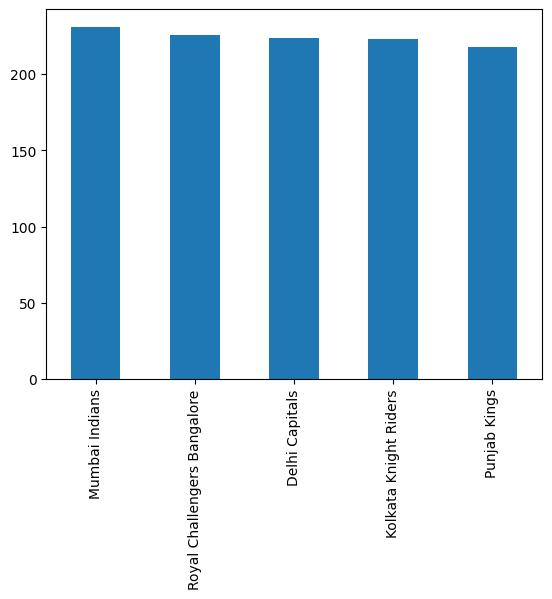

In [51]:
# code here
import matplotlib.pyplot as plt
(matches['Team1'].value_counts() +matches['Team2'].value_counts()).sort_values(ascending=False).head(5).plot(kind='bar')


###`Q-7:` Player who got Most no. of player of the match award playing against Mumbai Indians.
> Just for this question assume player of the match award is given to players from winning team. Although this is true in most of the cases.


In [64]:
# code here
wining =matches[(matches['Team1']=='Mumbai Indians') | (matches['Team2']=='Mumbai Indians')]
wining[wining['WinningTeam'] != 'Mumbai Indians']['Player_of_Match'].value_counts().sort_values(ascending=False)


Player_of_Match
KL Rahul         4
SK Raina         4
SPD Smith        4
JC Buttler       3
KC Sangakkara    3
                ..
PP Ojha          1
Sohail Tanvir    1
KD Karthik       1
AC Gilchrist     1
MV Boucher       1
Name: count, Length: 68, dtype: int64

###`Q-8:` Team1 vs Team2 Dashbord
Create a function which will take two string(name of two teams) as input. Show win Loss record between them and player getting most player of the match award in matches between these two teams.
```
team1_vs_team2('Kolkata Knight Riders','Chennai Super Kings')
```

In [77]:
# code here
def team1_vs_team2(team1,team2):
    val = matches[(matches['Team1']==team1) & (matches['Team2']==team2) | (matches['Team2']==team1) & (matches['Team1']==team2)]
    playerAward=val['Player_of_Match'].value_counts()
    win=val['WinningTeam'].value_counts()
    print(playerAward.head(1))
    print(win)

   
team1_vs_team2('Kolkata Knight Riders','Chennai Super Kings')

Player_of_Match
RA Jadeja    3
Name: count, dtype: int64
WinningTeam
Chennai Super Kings      17
Kolkata Knight Riders     9
Name: count, dtype: int64


### `Q-9:` Find out the top 7 cities where the matches of Kolkata Knight Riders are played frequently and plot the result as bar chart.

*`.plot(kind = "bar")` can help you to plot the bar chart. Also you can learn more about this method from [here](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.plot.html)*



<Axes: xlabel='City'>

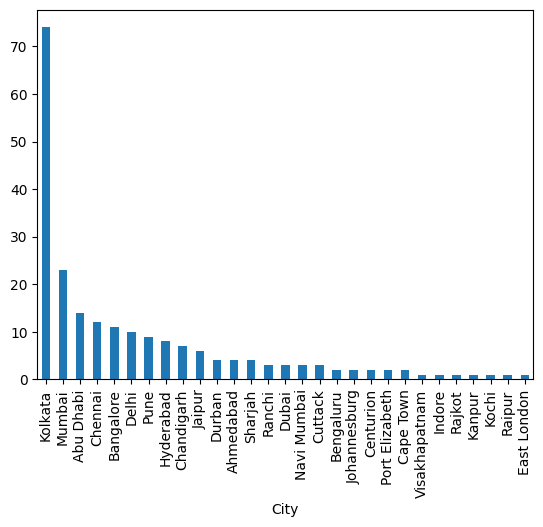

In [79]:
# code here
kkr=matches[(matches['Team1']=='Kolkata Knight Riders') | (matches['Team2']=='Kolkata Knight Riders')]
kkr['City'].value_counts().plot(kind='bar')

### `Q-10:` Find out the average margin for the team Mumbai Indians for only the session 2011.

In [83]:
# code here
float(matches[(matches['Team1']=='Mumbai Indians') | (matches['Team2']=='Mumbai Indians') & (matches['Season']=="2011")]['Margin'].mean())


18.5